# Experiments for the report
Everything the *Modeling* section of the report is based on:
1. baselines and other models, on a validation period, to choose the model
2. how far to look back, on the same validation period
3. the final test of the chosen model, from 2021 until `END`
4. what the model looks at (feature importance)
5. where it goes wrong
6. could you make money with it?

It uses the same model and walk-forward test as `ML2.ipynb` and the website (`btc_model.py`).
Prices stop at `END`, so the numbers stay the same every time this runs. The figures are saved to `report/figures/`.
Running everything takes about 10 minutes, mostly for gradient boosting.

Guesses start at the start of each period (every hour, every Monday, every 1st of the month), like on the website.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge

from btc_data import HOUR, load_prices
from btc_model import PERIODS, WINDOW, Model, build_dataset, luck, report, walk_forward

VALIDATION = (pd.Timestamp("2019-07-01"), pd.Timestamp("2021-01-01"))  # for choosing the model and the window
TEST = (pd.Timestamp("2021-01-01"), pd.Timestamp("2026-10-26"))        # looked at once, with the chosen model
END = TEST[1]
FIGURES = Path("report/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

prices = load_prices()[: END - HOUR]
print(f"{prices.index[0]} -> {prices.index[-1]}, {prices['Close'].isna().sum()} missing hours")

2018-01-01 00:00:00 -> 2026-10-25 23:00:00, 122 missing hours


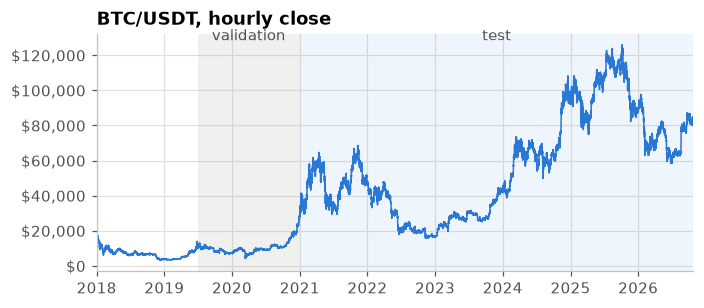

In [2]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(prices.index, prices["Close"], color=BLUE, lw=1)
ax.axvspan(*VALIDATION, color=GRAY, alpha=0.12, lw=0)
ax.axvspan(*TEST, color=BLUE, alpha=0.07, lw=0)
for (start, end), label in [(VALIDATION, "validation"), (TEST, "test")]:
    ax.text(start + (end - start) / 2, prices["Close"].max() * 1.02, label, ha="center", color="#52514e")
ax.set_title("BTC/USDT, hourly close")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.margins(x=0)
fig.savefig(FIGURES / "price_history.png")
plt.show()

## 1. Baselines and other models (validation period)
Every model gets the same features and the same walk-forward test: it re-learns at the start of every month,
only from periods that were over by then.

Baselines that need no machine learning:
- **same as last price**: guess no change. Hard to beat on the price itself.
- **always up**: BTC mostly went up, so this is the honest coin flip to beat for the direction.
- **same direction as last period**: momentum.
- **opposite of last period**: mean reversion.
- **average move** for the size of the move: always guess the average move. The move skill compares with this one, so it scores 0.
- **last period's move**: guess that the next move is as big as the last one.

In [3]:
MODELS = {
    "Linear regression": LinearRegression(),
    "Ridge (ours)": Ridge(),
    "Ridge, strong (alpha=1000)": Ridge(alpha=1000),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=0),
}
COLUMNS = ["right direction %", "chance it's luck %", "confident right direction %", "confident chance it's luck %",
           "inside 80% range %", "move size better than average guess %", "accuracy %"]


def baselines(result: pd.DataFrame, data: pd.DataFrame, hours: int) -> dict:
    """Scores of the guesses that need no machine learning, on the same periods as `result`."""
    at = result.index - HOUR  # the hour each guess is made
    up = result["change"] > 0
    last_change = data.loc[at, "price1"].to_numpy()
    last_move = data["change"].shift(hours).abs().loc[at].to_numpy()  # the move of the period that just ended
    real_move = result["change"].abs()
    average_miss = (result["average_move"] - real_move).abs().mean()

    def direction(right):
        return {"right direction %": right.mean() * 100, "chance it's luck %": luck(right) * 100}

    return {
        "Same as last price": {"accuracy %": report(result)["same-as-last-price %"]},
        "Always up": direction(up),
        "Same direction as last period": direction(up == (last_change > 0)),
        "Opposite of last period": direction(up == (last_change < 0)),
        "Average move": {"move size better than average guess %": 0.0},
        "Last period's move": {"move size better than average guess %": (1 - (last_move - real_move).abs().mean() / average_miss) * 100},
    }


def compare(start, end, models=MODELS, window=WINDOW) -> dict:
    tables, results = {}, {}
    for name, hours in PERIODS.items():
        data, features = build_dataset(prices, hours, window)
        results[name] = {m: walk_forward(data, features, name, start, end, regressor) for m, regressor in models.items()}
        rows = baselines(results[name]["Ridge (ours)"], data, hours)
        rows |= {m: {c: report(r)[c] for c in COLUMNS} for m, r in results[name].items()}
        tables[name] = pd.DataFrame(rows).T.reindex(columns=COLUMNS)
    return tables, results


validation_tables, validation_results = compare(*VALIDATION)
for name, table in validation_tables.items():
    print(f"\n{name.upper()} BY {name.upper()}, validation ({len(validation_results[name]['Ridge (ours)'])} guesses)")
    display(table.round(2).fillna("-"))


HOUR BY HOUR, validation (13116 guesses)


,right direction %,chance it's luck %,confident right direction %,confident chance it's luck %,inside 80% range %,move size better than average guess %,accuracy %
Same as last price,-,-,-,-,-,-,99.57
Always up,51.09,0.64,-,-,-,-,-
Same direction as last period,44.97,100.0,-,-,-,-,-
Opposite of last period,55.02,0.0,-,-,-,-,-
Average move,-,-,-,-,-,0.0,-
Last period's move,-,-,-,-,-,-6.21,-
Linear regression,54.12,0.0,55.11,0.0,80.26,18.84,99.58
Ridge (ours),54.12,0.0,55.11,0.0,80.26,18.84,99.58
"Ridge, strong (alpha=1000)",54.26,0.0,55.03,0.0,80.23,18.78,99.58
Gradient boosting,52.17,0.0,55.14,0.0,78.07,18.18,99.57



WEEK BY WEEK, validation (79 guesses)


,right direction %,chance it's luck %,confident right direction %,confident chance it's luck %,inside 80% range %,move size better than average guess %,accuracy %
Same as last price,-,-,-,-,-,-,95.66
Always up,59.49,5.73,-,-,-,-,-
Same direction as last period,49.37,58.89,-,-,-,-,-
Opposite of last period,50.63,50.0,-,-,-,-,-
Average move,-,-,-,-,-,0.0,-
Last period's move,-,-,-,-,-,-36.18,-
Linear regression,55.7,18.41,47.06,68.55,75.95,7.98,95.56
Ridge (ours),55.7,18.41,47.06,68.55,75.95,7.98,95.56
"Ridge, strong (alpha=1000)",53.16,32.65,41.67,80.62,77.22,5.93,95.57
Gradient boosting,59.49,5.73,60.0,25.17,30.38,-5.6,95.35



MONTH BY MONTH, validation (19 guesses)


,right direction %,chance it's luck %,confident right direction %,confident chance it's luck %,inside 80% range %,move size better than average guess %,accuracy %
Same as last price,-,-,-,-,-,-,92.37
Always up,73.68,3.18,-,-,-,-,-
Same direction as last period,63.16,17.96,-,-,-,-,-
Opposite of last period,36.84,91.65,-,-,-,-,-
Average move,-,-,-,-,-,0.0,-
Last period's move,-,-,-,-,-,-15.74,-
Linear regression,52.63,50.0,33.33,89.06,63.16,1.41,89.28
Ridge (ours),52.63,50.0,33.33,89.06,63.16,1.44,89.28
"Ridge, strong (alpha=1000)",47.37,67.62,20.0,96.88,68.42,2.77,90.06
Gradient boosting,26.32,99.04,30.0,94.53,5.26,-8.6,86.87


## 2. How far to look back? (validation period)
`WINDOW` is how many periods the model looks back. Tried on the validation period only.

In [4]:
rows = {}
for window in [1, 2, 4, 8, 16]:
    for name, hours in PERIODS.items():
        data, features = build_dataset(prices, hours, window)
        try:
            s = report(walk_forward(data, features, name, *VALIDATION))
        except ValueError:  # looks back further than the data goes
            continue
        rows[(name, window)] = {c: s[c] for c in ["guesses", "right direction %", "chance it's luck %", "inside 80% range %",
                                                  "move size better than average guess %"]}
windows = pd.DataFrame(rows).T
windows.index.names = ["period", "window"]
windows.round(2)

,,guesses,right direction %,chance it's luck %,inside 80% range %,move size better than average guess %
period,window,,,,,
hour,1,13149.0,54.93,0.00,80.15,18.78
week,1,79.0,45.57,81.59,77.22,6.19
month,1,19.0,52.63,50.00,73.68,0.90
hour,2,13138.0,54.09,0.00,80.21,18.79
week,2,79.0,54.43,24.99,75.95,6.42
month,2,19.0,42.11,82.04,73.68,2.53
hour,4,13116.0,54.12,0.00,80.26,18.84
week,4,79.0,55.70,18.41,75.95,7.98
month,4,19.0,52.63,50.00,63.16,1.44


## 3. Final test (2021 until `END`)
The chosen model (ridge, window 4) and the baselines on the test period. The other models are shown too, to see if the
choice held up, but they were not used to choose anything.

In [5]:
test_tables, test_results = compare(*TEST)
for name, table in test_tables.items():
    print(f"\n{name.upper()} BY {name.upper()}, test ({len(test_results[name]['Ridge (ours)'])} guesses)")
    display(table.round(2).fillna("-"))
results = {name: r["Ridge (ours)"] for name, r in test_results.items()}


HOUR BY HOUR, test (50927 guesses)


,right direction %,chance it's luck %,confident right direction %,confident chance it's luck %,inside 80% range %,move size better than average guess %,accuracy %
Same as last price,-,-,-,-,-,-,99.62
Always up,50.49,1.37,-,-,-,-,-
Same direction as last period,47.26,100.0,-,-,-,-,-
Opposite of last period,52.74,0.0,-,-,-,-,-
Average move,-,-,-,-,-,0.0,-
Last period's move,-,-,-,-,-,-2.11,-
Linear regression,52.61,0.0,54.99,0.0,79.42,22.63,99.62
Ridge (ours),52.61,0.0,54.99,0.0,79.42,22.63,99.62
"Ridge, strong (alpha=1000)",52.58,0.0,54.98,0.0,79.42,22.6,99.62
Gradient boosting,50.78,0.02,52.12,0.0,78.58,22.57,99.62



WEEK BY WEEK, test (303 guesses)


,right direction %,chance it's luck %,confident right direction %,confident chance it's luck %,inside 80% range %,move size better than average guess %,accuracy %
Same as last price,-,-,-,-,-,-,96.44
Always up,50.83,40.91,-,-,-,-,-
Same direction as last period,48.51,71.71,-,-,-,-,-
Opposite of last period,51.49,32.29,-,-,-,-,-
Average move,-,-,-,-,-,0.0,-
Last period's move,-,-,-,-,-,-21.71,-
Linear regression,47.52,82.1,48.96,62.02,75.91,10.22,96.33
Ridge (ours),47.52,82.1,48.96,62.02,75.91,10.22,96.33
"Ridge, strong (alpha=1000)",47.19,84.95,52.87,33.41,76.57,10.06,96.33
Gradient boosting,47.85,78.94,52.94,35.82,45.87,-6.5,95.84



MONTH BY MONTH, test (69 guesses)


,right direction %,chance it's luck %,confident right direction %,confident chance it's luck %,inside 80% range %,move size better than average guess %,accuracy %
Same as last price,-,-,-,-,-,-,92.49
Always up,57.97,11.42,-,-,-,-,-
Same direction as last period,50.72,50.0,-,-,-,-,-
Opposite of last period,49.28,59.5,-,-,-,-,-
Average move,-,-,-,-,-,0.0,-
Last period's move,-,-,-,-,-,-26.69,-
Linear regression,57.97,11.42,60.0,30.36,79.71,-6.93,91.8
Ridge (ours),57.97,11.42,60.0,30.36,79.71,-6.92,91.8
"Ridge, strong (alpha=1000)",57.97,11.42,56.25,40.18,79.71,-5.69,91.82
Gradient boosting,55.07,23.52,50.0,58.41,26.09,-11.16,90.21


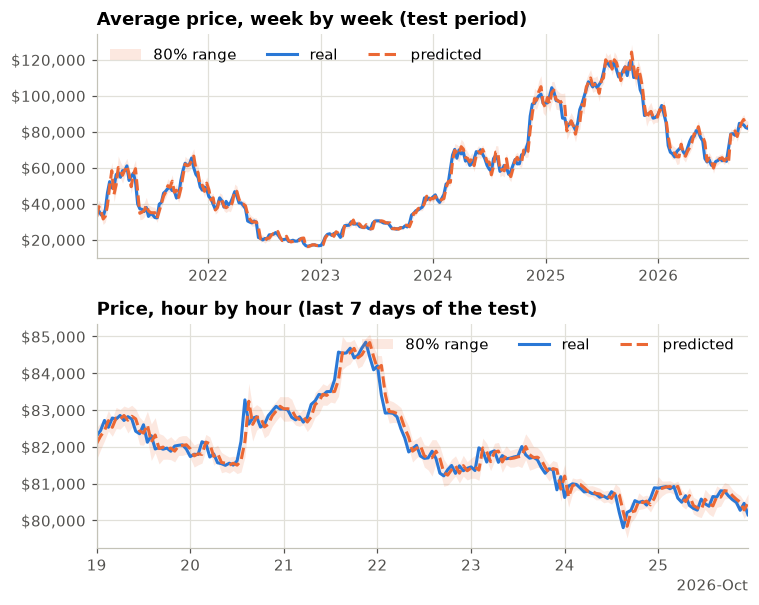

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(7, 5.6))
for ax, (name, shown) in zip(axes, [("week", results["week"]), ("hour", results["hour"].tail(24 * 7))]):
    ax.fill_between(shown.index, shown["low"], shown["high"], color=ORANGE, alpha=0.15, lw=0, label="80% range")
    ax.plot(shown.index, shown["real"], color=BLUE, label="real")
    ax.plot(shown.index, shown["predicted"], color=ORANGE, ls="--", label="predicted")
    ax.set_title("Average price, week by week (test period)" if name == "week" else "Price, hour by hour (last 7 days of the test)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.margins(x=0)
    ax.legend(loc="upper left" if name == "week" else "upper right", ncols=3)
fig.tight_layout()
fig.savefig(FIGURES / "predicted_vs_real.png")
plt.show()

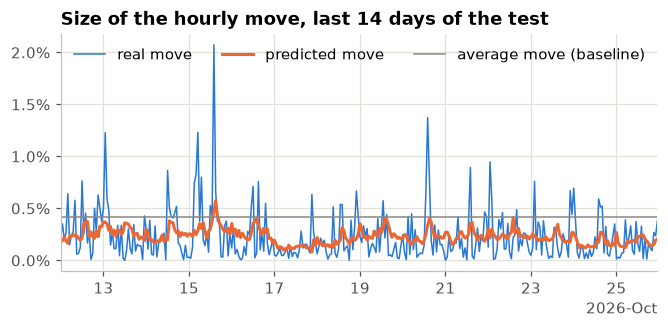

In [7]:
shown = results["hour"].tail(24 * 14)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(shown.index, shown["change"].abs() * 100, color=BLUE, lw=1, label="real move")
ax.plot(shown.index, shown["move"] * 100, color=ORANGE, label="predicted move")
ax.axhline(shown["average_move"].iloc[-1] * 100, color=GRAY, lw=1, label="average move (baseline)")
ax.set_title("Size of the hourly move, last 14 days of the test")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.1f}%"))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.margins(x=0)
ax.legend(loc="upper left", ncols=3)
fig.savefig(FIGURES / "move_size.png")
plt.show()

## 4. What does the model look at?
The features are scaled before the ridge regression, so the size of each coefficient shows how much the model
leans on that feature. The models here learned from all prices until `END`, like the one the website uses.

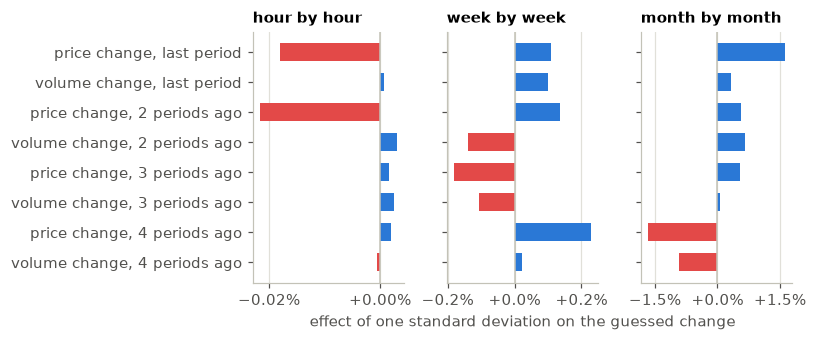

,hour,week,month
price1,-0.018,0.109,1.631
volume1,0.001,0.099,0.337
price2,-0.022,0.135,0.561
volume2,0.003,-0.138,0.669
price3,0.002,-0.182,0.535
volume3,0.003,-0.106,0.063
price4,0.002,0.230,-1.674
volume4,-0.001,0.024,-0.921


In [8]:
final = {}
for name, hours in PERIODS.items():
    data, features = build_dataset(prices, hours)
    model = Model(features).fit(data)
    final[name] = {
        "change": pd.Series(model.change_model[-1].coef_, index=features["change"]),
        "move": pd.Series(model.move_model[-1].coef_, index=features["move"]),
    }

NAMES = {}
for k in range(1, WINDOW + 1):
    ago = "last period" if k == 1 else f"{k} periods ago"
    NAMES[f"price{k}"], NAMES[f"volume{k}"] = f"price change, {ago}", f"volume change, {ago}"

fig, axes = plt.subplots(1, 3, figsize=(7.5, 3.2), sharey=True)
for ax, name in zip(axes, PERIODS):
    coef = final[name]["change"] * 100  # in % of price
    ax.barh([NAMES[f] for f in coef.index], coef, color=[BLUE if c > 0 else RED for c in coef], height=0.6)
    ax.axvline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"{name} by {name}", fontsize=10)
    ax.xaxis.set_major_locator(MaxNLocator(3, symmetric=True))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:+.2f}%" if name == "hour" else "{x:+.1f}%"))
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
axes[1].set_xlabel("effect of one standard deviation on the guessed change")
fig.tight_layout()
fig.savefig(FIGURES / "change_coefficients.png")
plt.show()
pd.DataFrame({name: final[name]["change"] * 100 for name in PERIODS}).round(3)

In [9]:
move_coef = pd.DataFrame({name: final[name]["move"] for name in PERIODS})
print("Move model, biggest coefficients (in log of the move size):")
move_coef.drop(index=[f for f in move_coef.index if f.startswith(("hour_", "day_"))]).round(3)

Move model, biggest coefficients (in log of the move size):


,hour,week,month
move1,-0.025,-0.125,-0.616
move2,0.013,-0.081,0.035
move3,0.020,-0.101,-0.080
move4,0.007,-0.036,0.047
move_168h,0.133,-0.125,-0.156
move_24h,0.207,0.120,0.106
move_720h,0.004,0.445,-0.616
range,0.236,0.190,1.351


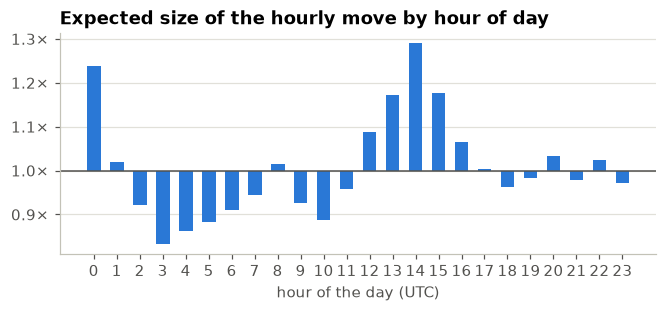

calmest hour: hour_3 0.83  wildest hour: hour_14 1.29


In [10]:
# Hour of day: the coefficients are per standard deviation, so divide by the scaler's standard deviation to get the
# effect of being in that hour. They are in log of the move, so exp() turns them into "times the usual move".
# The 24 hours share one intercept, so they are shown relative to their mean.
hours_of_day = [f"hour_{h}" for h in range(24)]
data, features = build_dataset(prices, PERIODS["hour"])
scaler = Model(features).fit(data).move_model[0]
scale = pd.Series(scaler.scale_, index=features["move"])[hours_of_day]
hour_effect = final["hour"]["move"][hours_of_day] / scale
hour_effect = np.exp(hour_effect - hour_effect.mean())
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(range(24), hour_effect - 1, bottom=1, color=BLUE, width=0.6)  # bars grow from "the usual move"
ax.axhline(1, color="#52514e", lw=1)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.1f}×"))
ax.set_xticks(range(24))
ax.set_xlabel("hour of the day (UTC)")
ax.set_title("Expected size of the hourly move by hour of day")
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "hour_of_day.png")
plt.show()
print("calmest hour:", hour_effect.idxmin(), round(hour_effect.min(), 2), " wildest hour:", hour_effect.idxmax(), round(hour_effect.max(), 2))

## 5. Where does it go wrong?

In [11]:
def by_group(result: pd.DataFrame, groups) -> pd.DataFrame:
    right = (result["predicted"] > result["last_price"]) == (result["change"] > 0)
    inside = result["real"].between(result["low"], result["high"])
    miss = (result["predicted"] - result["real"]).abs() / result["real"] * 100
    out = pd.DataFrame({"right": right, "confident": result["confident"], "inside": inside, "miss": miss})
    return out.groupby(groups).apply(lambda g: pd.Series({
        "guesses": len(g),
        "right direction %": g["right"].mean() * 100,
        "chance it's luck %": luck(g["right"]) * 100,
        "confident right direction %": g.loc[g["confident"], "right"].mean() * 100,
        "inside 80% range %": g["inside"].mean() * 100,
        "average miss %": g["miss"].mean(),
    }))


hour_by_year = by_group(results["hour"], results["hour"].index.year)
hour_by_year.round(2)

,guesses,right direction %,chance it's luck %,confident right direction %,inside 80% range %,average miss %
2021,8717.0,52.05,0.01,53.06,78.74,0.62
2022,8760.0,53.09,0.00,57.69,80.33,0.43
2023,8754.0,53.51,0.00,55.19,80.65,0.27
2024,8784.0,53.06,0.00,54.54,78.93,0.37
2025,8760.0,51.61,0.13,53.89,78.73,0.31
2026,7152.0,52.27,0.01,55.60,79.04,0.29


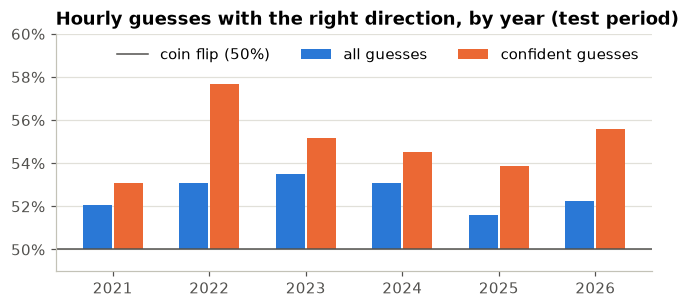

In [12]:
fig, ax = plt.subplots(figsize=(7, 2.8))
x = np.arange(len(hour_by_year))
ax.bar(x - 0.16, hour_by_year["right direction %"] - 50, bottom=50, width=0.3, color=BLUE, label="all guesses")
ax.bar(x + 0.16, hour_by_year["confident right direction %"] - 50, bottom=50, width=0.3, color=ORANGE, label="confident guesses")
ax.axhline(50, color="#52514e", lw=1, label="coin flip (50%)")
ax.set_xticks(x, hour_by_year.index)
ax.set_ylim(49, 60)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
ax.set_title("Hourly guesses with the right direction, by year (test period)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncols=3)
fig.savefig(FIGURES / "direction_by_year.png")
plt.show()

Is the 80% range right in calm and wild times? The guesses are split in three by how big a move the model expected.

In [13]:
calm_or_wild = {
    name: by_group(r, pd.qcut(r["move"], 3, labels=["calm", "normal", "wild"]))[["guesses", "inside 80% range %", "average miss %"]]
    for name, r in results.items()
}
pd.concat(calm_or_wild).round(2)

guesses  inside 80% range %  average miss %
      move                                               
hour  calm    16976.0               80.01            0.19
      normal  16975.0               79.22            0.34
      wild    16976.0               79.02            0.61
week  calm      101.0               73.27            3.05
      normal    101.0               77.23            3.10
      wild      101.0               77.23            4.86
month calm       23.0               60.87            8.07
      normal     23.0               91.30            7.41
      wild       23.0               86.96            9.12

In [14]:
week = results["week"]
misses = week.assign(miss=(week["predicted"] - week["real"]) / week["real"] * 100)
misses = misses.reindex(misses["miss"].abs().sort_values(ascending=False).index).head(8)
misses.assign(real_change=misses["change"] * 100)[["last_price", "predicted", "real", "low", "high", "miss", "real_change"]].round(1)

,last_price,predicted,real,low,high,miss,real_change
2022-06-13,26574.5,26902.0,21195.4,25014.3,28927.7,26.9,-20.2
2021-02-22,57408.6,58384.8,48790.8,54587.8,62989.7,19.7,-15.0
2021-05-17,46431.5,46724.0,39819.9,42647.7,51323.5,17.3,-14.2
2022-11-07,20905.6,20983.4,17911.2,20187.7,21840.5,17.2,-14.3
2021-02-08,38795.7,39210.3,46171.6,35881.1,43247.8,-15.1,19.0
2021-05-10,58240.8,59471.1,52218.9,55205.7,64284.1,13.9,-10.3
2026-06-01,73674.4,74106.0,65139.4,71804.9,76516.4,13.8,-11.6
2023-03-13,21997.1,22119.1,25459.6,20913.3,23427.8,-13.1,15.7


## 6. Could you make money with it?
A simple test of the business value: at each guess, buy if the model says up, sell (short) if it says down, and get out at the
end of the period. Binance charges about 0.1% per trade, so a round trip costs about 0.2%.
For weeks and months the exit is spread over the period, since the guess is the average price.

In [15]:
FEE = 0.2  # % per round trip
rows = {}
for name, r in results.items():
    gain = np.sign(r["predicted"] - r["last_price"]) * r["change"] * 100
    for who, g in [("all", gain), ("confident", gain[r["confident"]])]:
        rows[(name, who)] = {"trades": len(g), "guessed up %": (g.index.isin(r.index[r["predicted"] > r["last_price"]])).mean() * 100,
                             "average gain per trade %": g.mean(), "after fees %": g.mean() - FEE,
                             "share of trades that won %": (g > 0).mean() * 100}
pd.DataFrame(rows).T.round(3)

trades  guessed up %  average gain per trade %  \
hour  all        50927.0        60.577                     0.002   
      confident  11207.0        73.115                     0.001   
week  all          303.0        88.119                    -0.127   
      confident     96.0       100.000                     0.108   
month all           69.0        79.710                     1.736   
      confident     15.0        93.333                     4.729   

                 after fees %  share of trades that won %  
hour  all              -0.198                      52.605  
      confident        -0.199                      54.992  
week  all              -0.327                      47.525  
      confident        -0.092                      48.958  
month all               1.536                      57.971  
      confident         4.529                      60.000